# Ex 9 — Dimensionality Reduction using PCA

**Dataset:** Bangalore Smart Building  
**Task:** predict `Building_Status` before and after PCA  
**Reg No:** URK24CS1021

In [1]:
print("URK24CS1021")

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

SEED = 1021
df = pd.read_csv("building_data.csv")
df.head()

URK24CS1021


,City,Area,Building_Type,Construction_Year,Number_of_Floors,Energy_Consumption_Per_SqM,Water_Usage_Per_Building,Waste_Recycled_Percentage,Occupancy_Rate,Indoor_Air_Quality,Smart_Devices_Count,Green_Certified,Maintenance_Resolution_Time,Last_Inspection_Date,Building_Status,Maintenance_Priority,Energy_Per_SqM,Number_of_Residents,Electricity_Bill
0,Bangalore,Yelahanka,Residential,1989,12,50.000000,477.681762,48.417266,81.814110,13.780635,6,0,7.211768,25-09-2023,Under Maintenance,High,174.835708,360,16408.008770
1,Bangalore,Whitefield,Institutional,1980,6,225.759107,200.000000,46.405516,45.109000,10.177771,10,0,34.139492,18-05-2024,Under Maintenance,High,143.086785,91,15230.425070
2,Bangalore,Koramangala,Industrial,2006,10,98.755927,200.000000,17.247585,48.526225,27.757026,2,1,6.224612,28-09-2023,Operational,Medium,182.384427,115,8117.632795
3,Bangalore,Jayanagar,Commercial,1985,1,68.470692,200.000000,57.719480,76.335921,1.519812,2,0,5.327398,17-10-2022,Closed,Low,226.151493,159,13030.707160
4,Bangalore,HSR Layout,Industrial,2006,12,50.000000,347.093644,26.936862,96.511319,1.874753,19,0,7.060854,25-04-2024,Closed,Medium,138.292331,258,25848.853740


In [2]:
print("URK24CS1021")

df.shape, df.isnull().sum().sum()

URK24CS1021


((1250, 19), np.int64(0))

In [3]:
print("URK24CS1021")

df.describe().round(2).T

URK24CS1021


,count,mean,std,min,25%,50%,75%,max
Construction_Year,1250.0,1996.74,15.70,1970.00,1983.00,1996.00,2010.00,2023.00
Number_of_Floors,1250.0,7.12,3.77,1.00,4.00,7.00,11.00,13.00
Energy_Consumption_Per_SqM,1250.0,108.75,72.18,50.00,50.00,72.87,154.66,250.00
Water_Usage_Per_Building,1250.0,647.02,485.19,200.00,200.00,451.64,1013.70,1500.00
Waste_Recycled_Percentage,1250.0,28.83,16.25,0.91,15.95,26.83,39.81,80.89
Occupancy_Rate,1250.0,77.29,15.09,17.60,68.05,80.36,88.98,99.92
Indoor_Air_Quality,1250.0,40.52,33.71,0.03,11.66,29.96,66.64,100.00
Smart_Devices_Count,1250.0,5.24,3.25,1.00,3.00,5.00,7.00,20.00
Green_Certified,1250.0,0.24,0.43,0.00,0.00,0.00,0.00,1.00
Maintenance_Resolution_Time,1250.0,9.62,6.87,5.00,5.94,7.61,10.51,72.00


### What are we predicting, and what is guessing worth?

In [4]:
print("URK24CS1021")

df["Building_Status"].value_counts()

URK24CS1021


Building_Status
Closed               436
Operational          411
Under Maintenance    403
Name: count, dtype: int64

### Prepare the features

In [5]:
print("URK24CS1021")

# City is the same for every row, the date is text
X = df.drop(columns=["Building_Status", "City", "Last_Inspection_Date"])
y = df["Building_Status"]

# PCA needs numbers, so text columns become 0/1 columns
X = pd.get_dummies(X, columns=["Area", "Building_Type", "Maintenance_Priority"],
                   drop_first=True).astype(float)
X.shape

URK24CS1021


(1250, 28)

In [6]:
print("URK24CS1021")

# split first, so the test rows never influence scaling or PCA
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)

scaler = StandardScaler().fit(X_train)
Xtr, Xte = scaler.transform(X_train), scaler.transform(X_test)
Xtr.shape, Xte.shape

URK24CS1021


((1000, 28), (250, 28))

### Before PCA

In [7]:
print("URK24CS1021")

results = []

def fit_and_score(name, model, A, B, label):
    start = time.perf_counter()
    model.fit(A, y_train)
    secs = time.perf_counter() - start
    acc = accuracy_score(y_test, model.predict(B))
    results.append({"Model": name, "Data": label, "Features": A.shape[1],
                    "Accuracy": round(acc, 4), "Time": round(secs, 4)})

fit_and_score("Logistic Regression", LogisticRegression(max_iter=2000), Xtr, Xte, "Original")
fit_and_score("Random Forest", RandomForestClassifier(random_state=SEED), Xtr, Xte, "Original")
pd.DataFrame(results)

URK24CS1021


,Model,Data,Features,Accuracy,Time
0,Logistic Regre...,Original,28,0.356,0.0181
1,Random Forest,Original,28,0.376,0.6291


### PCA and the explained variance

In [8]:
print("URK24CS1021")

pca_full = PCA(random_state=SEED).fit(Xtr)
cum = pca_full.explained_variance_ratio_.cumsum()
cum.round(3)

URK24CS1021


array([0.06 , 0.113, 0.164, 0.211, 0.255, 0.298, 0.341, 0.382, 0.422,
       0.461, 0.5  , 0.539, 0.578, 0.615, 0.652, 0.688, 0.723, 0.757,
       0.79 , 0.822, 0.854, 0.884, 0.914, 0.943, 0.969, 0.985, 0.997,
       1.   ])

URK24CS1021


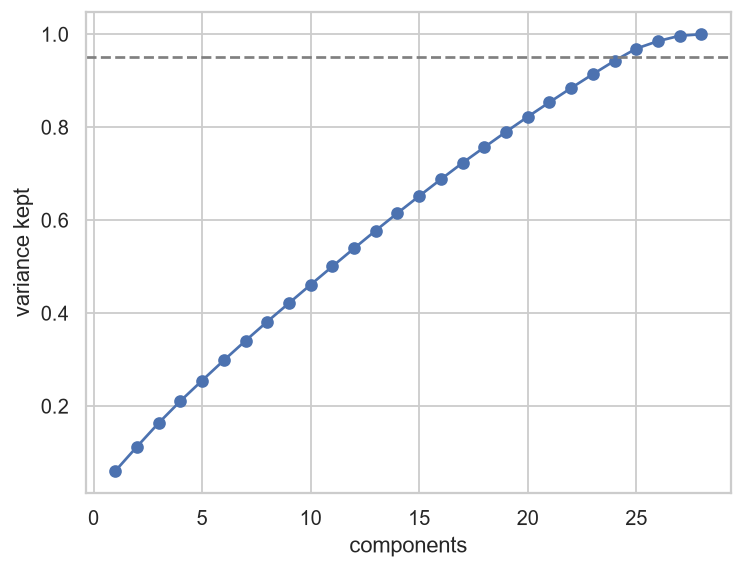

In [9]:
print("URK24CS1021")

plt.plot(range(1, len(cum) + 1), cum, marker='o')
plt.axhline(0.95, linestyle='--', color='grey')
plt.xlabel('components')
plt.ylabel('variance kept')
plt.show()

### After PCA

In [10]:
print("URK24CS1021")

pca95 = PCA(n_components=0.95, random_state=SEED).fit(Xtr)
pca2 = PCA(n_components=2, random_state=SEED).fit(Xtr)

for pca, label in ((pca95, "PCA 95%"), (pca2, "PCA 2")):
    A, B = pca.transform(Xtr), pca.transform(Xte)
    fit_and_score("Logistic Regression", LogisticRegression(max_iter=2000), A, B, label)
    fit_and_score("Random Forest", RandomForestClassifier(random_state=SEED), A, B, label)
pd.DataFrame(results)

URK24CS1021


,Model,Data,Features,Accuracy,Time
0,Logistic Regre...,Original,28,0.356,0.0181
1,Random Forest,Original,28,0.376,0.6291
2,Logistic Regre...,PCA 95%,25,0.344,0.0112
3,Random Forest,PCA 95%,25,0.308,0.9434
4,Logistic Regre...,PCA 2,2,0.360,0.0092
5,Random Forest,PCA 2,2,0.372,0.5434


### Why so little change? Check the correlation

In [11]:
print("URK24CS1021")

corr = X.corr().abs().values
np.fill_diagonal(corr, 0)
corr.max().round(3)

URK24CS1021


np.float64(0.512)

URK24CS1021


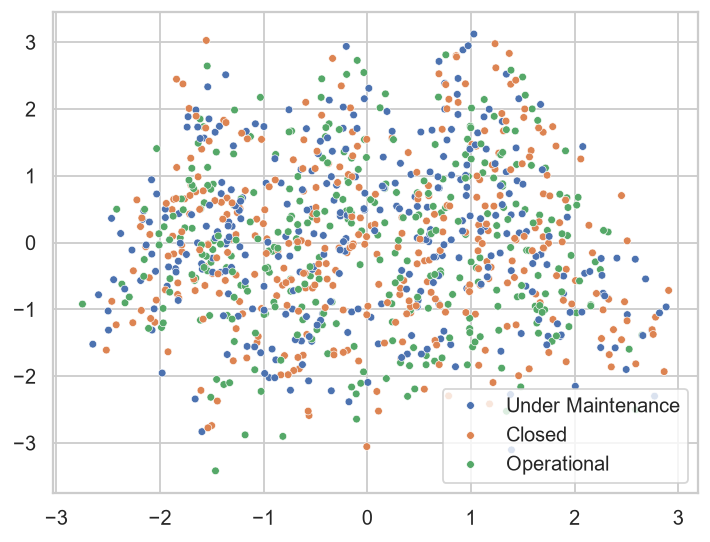

In [12]:
print("URK24CS1021")

pts = pca2.transform(Xtr)
sns.scatterplot(x=pts[:, 0], y=pts[:, 1], hue=y_train.values, s=18)
plt.show()